# Figure 7: spectral fidelity of the compression

Section 4.5, `fig:spectral_fid`. The mean power per spherical harmonic
degree of the inputs, their reconstructions and the residuals with a
16th-to-84th percentile band, and below it the cosine similarity
between input and reconstructed coefficient vectors within each
degree.

Spectral quantities are whole-sphere by construction, since a spatial
mask is not diagonal in the harmonic basis. The per-degree grouping of
the real-packed vector comes from `operator_analysis.degree_map`,
which derives the degree of each entry by pushing unit vectors through
`real_to_coeffs` rather than assuming the packing.

## Imports

In [1]:
from _setup import *

from starspot_sbi.pipeline import decode_ceiling_coeffs

from operator_analysis import degree_map

## Setup

The sample the VAE figures share.

In [2]:
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SAMPLE_FAMILY = 'phot_axay'

## Selecting the sample

The 5000 surfaces the holdout run scored, so the VAE figures and the
Section 7 figures describe one sample.

In [3]:
idx = load_metrics(SAMPLE_FAMILY)['idx'].values
coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                        f'surface_{i:07d}.npy'))
                   for i in idx])
truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
print(f'{len(idx)} holdout surfaces, the same 5000 the run scored')

5000 holdout surfaces, the same 5000 the run scored


## Inference

Reconstructs every surface, then takes the three spectra and the
within-degree cosine similarity.

In [4]:
vae, stats = load_autoencoder(device=DEVICE)
rec = decode_ceiling_coeffs(coeffs, vae, stats, device=DEVICE)

C_true = power_spectrum(truth_real)
C_rec = power_spectrum(rec)
C_resid = power_spectrum(truth_real - rec)
ells = np.arange(L_MAX + 1)

ell_of = degree_map(L_MAX)
cos_l = np.empty((len(idx), L_MAX + 1))
for l in ells:
    t = truth_real[:, ell_of == l]
    r = rec[:, ell_of == l]
    cos_l[:, l] = (t * r).sum(axis=1) / np.maximum(
        np.linalg.norm(t, axis=1) * np.linalg.norm(r, axis=1), 1e-30)
ratio = C_resid.mean(0)[1:] / C_true.mean(0)[1:]
print('spectra and per-degree cosines done')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


spectra and per-degree cosines done


## Plotting

Draws the figure from the names bound above.

Text(0.5, 0, 'Degree $\\ell$')

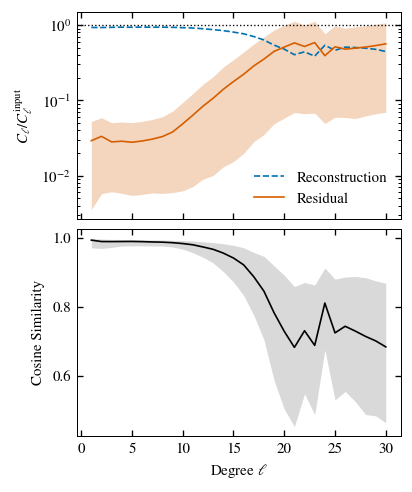

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(COL, COL * 1.2),
                               sharex=True)
mean_true = C_true.mean(0)
ax1.semilogy(ells[1:], C_rec.mean(0)[1:] / mean_true[1:], color=BLUE,
             ls='--', label='Reconstruction')
ax1.semilogy(ells[1:], ratio, color=RED, label='Residual')
ax1.fill_between(ells[1:],
                 np.percentile(C_resid, 16, axis=0)[1:] / mean_true[1:],
                 np.percentile(C_resid, 84, axis=0)[1:] / mean_true[1:],
                 color=RED, alpha=0.25, lw=0)
ax1.axhline(1.0, color='black', ls=':', lw=0.8)
ax1.set_ylabel(r'$C_\ell / C_\ell^{\rm input}$')
ax1.legend()
ax2.plot(ells[1:], np.median(cos_l, axis=0)[1:], color='black')
ax2.fill_between(ells[1:], np.percentile(cos_l, 16, axis=0)[1:],
                 np.percentile(cos_l, 84, axis=0)[1:],
                 color='black', alpha=0.15, lw=0)
ax2.set_ylabel('Cosine Similarity')
ax2.set_xlabel(r'Degree $\ell$')


## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 4.5 text
quotes: where the residual sits one to two orders below the input,
where it closes to within a factor of a few, and the non-monotonic
cosine similarity tracking the input power.

In [6]:
save_fig(fig, 'fig07_spectral_fid')
print('per-degree residual-to-input power ratio and median cosine:')
for l in ells[1:]:
    print(f'  l {l:2d}: ratio {ratio[l - 1]:.3f}  cos '
          f'{np.median(cos_l[:, l]):.3f}')
for lo, hi in ((22, 24), (15, 21)):
    band = ratio[lo - 1:hi]
    print(f'residual/input ratio, l {lo} to {hi}: {band.min():.3f} to '
          f'{band.max():.3f}')
print(f'largest input power above l = 10 is at l = '
      f'{10 + np.argmax(C_true.mean(0)[10:])}')

wrote notebooks/paper/figs/fig07_spectral_fid.pdf, notebooks/paper/figs/fig07_spectral_fid.png
per-degree residual-to-input power ratio and median cosine:
  l  1: ratio 0.029  cos 0.994
  l  2: ratio 0.033  cos 0.990
  l  3: ratio 0.028  cos 0.989
  l  4: ratio 0.029  cos 0.990
  l  5: ratio 0.028  cos 0.990
  l  6: ratio 0.029  cos 0.989
  l  7: ratio 0.031  cos 0.988
  l  8: ratio 0.033  cos 0.988
  l  9: ratio 0.038  cos 0.986
  l 10: ratio 0.049  cos 0.984
  l 11: ratio 0.064  cos 0.980
  l 12: ratio 0.084  cos 0.974
  l 13: ratio 0.107  cos 0.967
  l 14: ratio 0.140  cos 0.956
  l 15: ratio 0.178  cos 0.942
  l 16: ratio 0.222  cos 0.922
  l 17: ratio 0.287  cos 0.887
  l 18: ratio 0.354  cos 0.845
  l 19: ratio 0.448  cos 0.783
  l 20: ratio 0.511  cos 0.729
  l 21: ratio 0.581  cos 0.682
  l 22: ratio 0.520  cos 0.731
  l 23: ratio 0.586  cos 0.688
  l 24: ratio 0.392  cos 0.811
  l 25: ratio 0.515  cos 0.725
  l 26: ratio 0.479  cos 0.744
  l 27: ratio 0.494  cos 0.730
  l 28: 